# Credit Card Fraud Detection on the Kaggle Credit Fraud Dataset
### Extreme class imbalance · Time-based validation · Cost-sensitive thresholding · SHAP explainability

**Problem.** Fewer than 0.2% of card transactions are fraudulent, yet each missed fraud costs real money, and
every false alarm costs analyst time and customer stress. This notebook builds a fraud detector on the
public *Credit Card Fraud Detection* dataset from Kaggle with a focus on: imbalance handling, and optimising **dollars** rather than accuracy.

**Dataset.** [Kaggle: Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)
(ULB Machine Learning Group & Worldline): European cardholders, two days in September 2013,
284,807 transactions, 492 frauds (0.172%). Features `V1`-`V28` are PCA components (anonymised for
confidentiality); only `Time` (seconds since the first transaction) and `Amount` are original.
Released under the Database Contents License (DbCL) v1.0.

> *Citation requested by the dataset authors:* Dal Pozzolo, Caelen, Johnson and Bontempi.
> "Calibrating Probability with Undersampling for Unbalanced Classification." IEEE CIDM, 2015.

**Pipeline**

| Step | Skill shown |
|---|---|
| 0. Load & clean | Robust loader (local file → kagglehub), duplicate handling |
| 1. EDA | Working with 0.17% positive class and what can (and cannot) be engineered from anonymised data |
| 2. Time-based split | Train → validation → test in chronological order |
| 3. Imbalance strategies | Class weights vs. under-sampling vs. SMOTE |
| 4. Model comparison | LR / Random Forest / LightGBM / Isolation Forest, with bootstrap confidence intervals |
| 5. Random vs. temporal split | Quantifying how much a random split flatters the model |
| 6. Cost-based threshold | Minimising dollar loss using `Amount` |
| 7. SHAP | Global drivers and per-alert explanations |
| 8. Business impact | ML metrics → money |

---
## Results at a glance

| Finding | Result |
|---|---|
| Best model (test PR-AUC, 95% CI) | best model is a tie, with RF at 0.813 [0.720, 0.889] and LightGBM at 0.788 [0.699, 0.872]|
| Random-classifier PR-AUC baseline | validation fraud rate = 0.0010 and test fraud rate = 0.0013 |
| Supervised vs. unsupervised (Isolation Forest) | supervised PR-AUC (0.813, 0.746, 0.788) performed better than Isolation Forest PR-AUC 0.048, so labels are worth about 16x. |
| Random-split PR-AUC vs. temporal-split PR-AUC | Over 10 random test splits, 0.064 PR-AUC (random minus chronological). |
| Cost reduction vs. no model at cost-optimal threshold | \$4,933 (64\%) compared to no model : 7,728 dollars |
| Cost reduction at F1-optimal threshold | \$3,984 (51.6%) |

## Load Packages and General Setup

In [50]:
# Uncomment to install dependencies (kagglehub, used only to auto-download the data)
# !pip install numpy pandas scikit-learn lightgbm shap imbalanced-learn matplotlib seaborn kagglehub

import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import shap
from IPython.display import display, Markdown

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from imblearn.over_sampling import SMOTE

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 160)

## Step 1. Load and clean the data

The loader tries two sources in order, so the notebook works on Kaggle, Colab or a laptop:

1. **Local file** `creditcard.csv` in the working directory or `./data/` (download from the Kaggle page above)
2. **`kagglehub`**, which downloads `mlg-ulb/creditcardfraud`

Then drop exact duplicate rows (so identical records can't land in both train and test) and sort chronologically.

In [51]:
def load_creditcard():
    for p in [Path("creditcard.csv"), Path("/kaggle/input/creditcardfraud/creditcard.csv")]:
        if p.exists():
            return pd.read_csv(p), f"local file: {p}"
    try:
        import kagglehub
        folder = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
        return pd.read_csv(Path(folder) / "creditcard.csv"), "kagglehub"
    except Exception as e:
        raise FileNotFoundError(
            "Could not load the dataset. Download creditcard.csv from "
            "https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud and place it next to this notebook.") from e

raw, source = load_creditcard()
print(f"Loaded from {source}: {raw.shape[0]:,} rows x {raw.shape[1]} columns")

# Clean dataset
n_dup = int(raw.duplicated().sum()) # number of duplicates.
raw = raw.drop_duplicates().sort_values("Time").reset_index(drop=True) # drop those duplicates.

print(f"Dropped {n_dup:,} exact duplicate rows -> {len(raw):,} transactions remain")
print(f"Fraud: {int(raw.Class.sum()):,} transactions ({raw.Class.mean():.3%}) | "
      f"time span: {raw.Time.max() / 3600:.1f} hours | missing values: {int(raw.isna().sum().sum())}")
raw.head()

Loaded from kagglehub: 284,807 rows x 31 columns
Dropped 1,081 exact duplicate rows -> 283,726 transactions remain
Fraud: 473 transactions (0.167%) | time span: 48.0 hours | missing values: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.000,1.192,0.266,0.166,0.448,0.060,-0.082,-0.079,0.085,-0.255,...,-0.226,-0.639,0.101,-0.340,0.167,0.126,-0.009,0.015,2.690,0
1,0.000,-1.360,-0.073,2.536,1.378,-0.338,0.462,0.240,0.099,0.364,...,-0.018,0.278,-0.110,0.067,0.129,-0.189,0.134,-0.021,149.620,0
2,1.000,-0.966,-0.185,1.793,-0.863,-0.010,1.247,0.238,0.377,-1.387,...,-0.108,0.005,-0.190,-1.176,0.647,-0.222,0.063,0.061,123.500,0
3,1.000,-1.358,-1.340,1.773,0.380,-0.503,1.800,0.791,0.248,-1.515,...,0.248,0.772,0.909,-0.689,-0.328,-0.139,-0.055,-0.060,378.660,0
4,2.000,-0.426,0.961,1.141,-0.168,0.421,-0.030,0.476,0.260,-0.569,...,-0.208,-0.560,-0.026,-0.371,-0.233,0.106,0.254,0.081,3.670,0


## Step 2. Exploratory data analysis (EDA)

With approximately 0.17% fraud, a model that labels everything as legitimate transactions will naively score at least 99.8% accuracy while catching **no** fraud. Therefore, one needs to evaluate with the metrics **PR-AUC** (average precision), **recall at fixed precision**, and **dollar cost**, as opposed to accuracy.

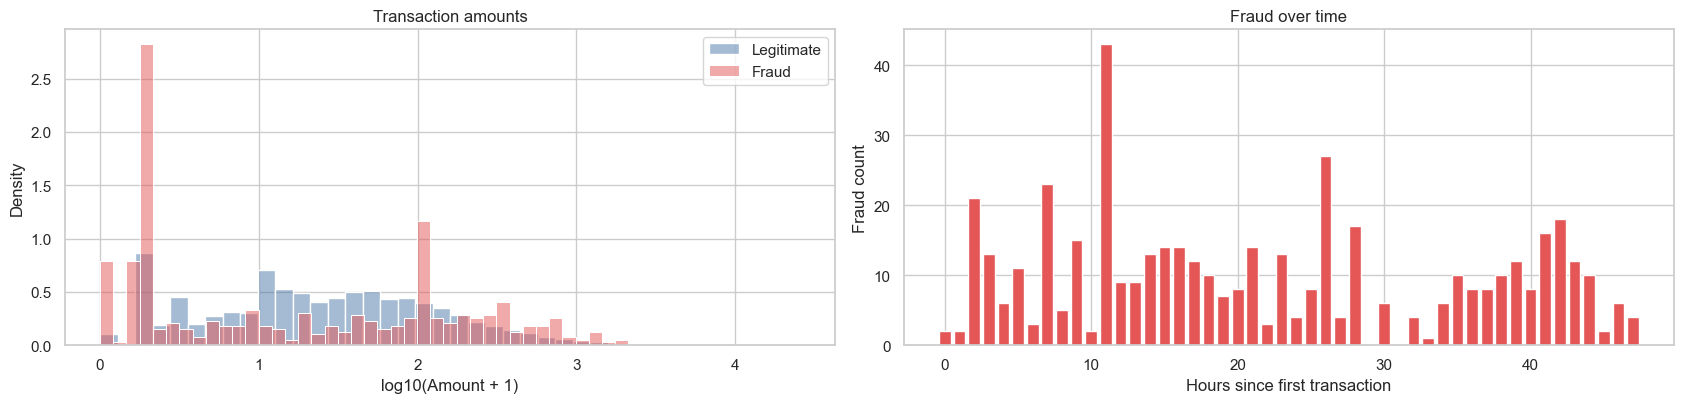

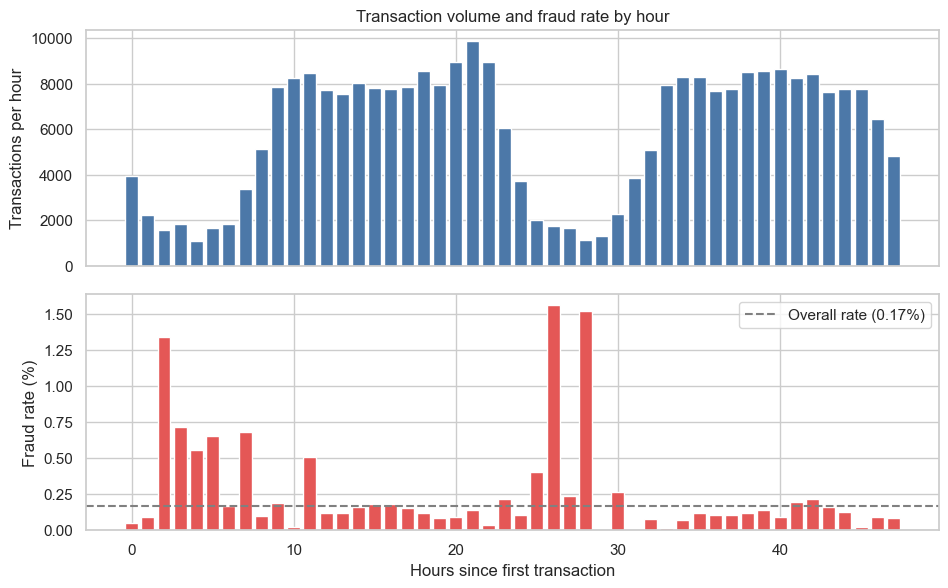

,transactions,frauds,fraud_rate_%
Time,,,
26,1735,27,1.556
28,1122,17,1.515
2,1573,21,1.335
3,1818,13,0.715
7,3366,23,0.683
5,1679,11,0.655
4,1082,6,0.555
11,8474,43,0.507


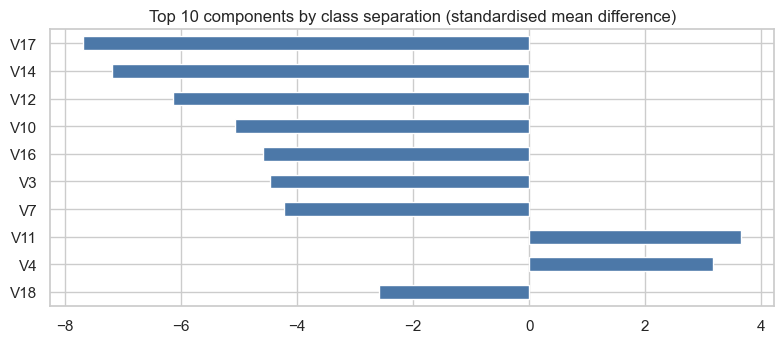

Median amount: legit $22.00 | fraud $9.82


In [52]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.2))

for lab, colour, name in [(0, "#4C78A8", "Legitimate"), (1, "#E45756", "Fraud")]:
    sns.histplot(np.log10(raw.loc[raw.Class == lab, "Amount"] + 1), stat="density", bins=40,
                 color=colour, alpha=.5, label=name, ax=ax[0])
ax[0].set_xlabel("log10(Amount + 1)"); ax[0].set_title("Transaction amounts"); ax[0].legend()

hr = (raw.Time // 3600).astype(int)
fraud_per_hour = raw.groupby(hr).Class.sum()
ax[1].bar(fraud_per_hour.index, fraud_per_hour.values, color="#E45756")
ax[1].set_xlabel("Hours since first transaction"); ax[1].set_ylabel("Fraud count"); ax[1].set_title("Fraud over time")
plt.tight_layout(); plt.show()

# Fraud rate vs. transaction volume per hour
hour_idx = (raw.Time // 3600).astype(int)
hourly = raw.groupby(hour_idx).agg(transactions=("Class", "size"), frauds=("Class", "sum"))
hourly["fraud_rate_%"] = hourly.frauds / hourly.transactions * 100
overall_rate = raw.Class.mean() * 100

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                       gridspec_kw={"height_ratios": [1, 1], "hspace": 0.12})

# Top: total volume per hour
ax[0].bar(hourly.index, hourly.transactions, color="#4C78A8")
ax[0].set_ylabel("Transactions per hour")
ax[0].set_title("Transaction volume and fraud rate by hour")

# Bottom: fraud rate per hour, with the overall rate as a reference line
ax[1].bar(hourly.index, hourly["fraud_rate_%"], color="#E45756")
ax[1].axhline(overall_rate, ls="--", c="grey", label=f"Overall rate ({overall_rate:.2f}%)")
ax[1].set_ylabel("Fraud rate (%)")
ax[1].set_xlabel("Hours since first transaction")
ax[1].legend()

plt.show()

# Hours with unusually high fraud rates, and how much volume backs them up
display(hourly.sort_values("fraud_rate_%", ascending=False).head(8))

# which anonymised components separate fraud from legit the most? (standardised mean difference)
vcols = [f"V{i}" for i in range(1, 29)]
# standardised mean difference in descending order of absolute difference. 
smd = ((raw.loc[raw.Class == 1, vcols].mean() - raw.loc[raw.Class == 0, vcols].mean()) / raw[vcols].std()).sort_values(key=abs, ascending=False)
fig, ax = plt.subplots(figsize=(8, 3.6))
# Top 10 components difference.
smd.head(10).iloc[::-1].plot.barh(ax=ax, color="#4C78A8"); ax.set_title("Top 10 components by class separation (standardised mean difference)")
plt.tight_layout(); plt.show()

print(f"Median amount: legit ${raw.loc[raw.Class == 0, 'Amount'].median():,.2f} | fraud ${raw.loc[raw.Class == 1, 'Amount'].median():,.2f}")

## Transaction Amounts plot

 Most frauds occur at low `Amount` values. The idea is that small `Amount` transactions are less likely to get flagged as fraud by people using there credit cards and won't flag them as fraud to banks.

## Fraud over time plot

This plot shows how many frauds occurred in each hour of the dataset's 48-hour window.

 Huge spike in the number of frauds at the 11th hour after the first transaction.

**1. Fraud is bursty, not steady.** The counts jump from 2-10 per hour to 43 at hour 11, with smaller spikes near hours 2, 7 and 26 (21-27 each). A single hour accounts for roughly 9% of frauds in the dataset. This is how fraud works, since a compromised card or card number gets used many times in a short window. It's also why the chronological split matters: a random split would put some transactions from a burst in training and others in test, which flatters the model.

**2. Fraud volume isn't uniform over time.** There's a busy first day, a quiet stretch around hours 28-34 (some hours with almost no fraud), and a second rise from about hour 35 to 45 before it tails off. So the train, validation and test splits don't contain equal amounts of fraud. The test set (the final 20% of transactions) lands in that last stretch, which fits the roughly 100 frauds.

**3. The data covers very little time.** There's a hint of a daily cycle (activity dips and rebounds around 24-30 hours), but two days can't show weekly patterns, seasonality or real drift. That's why the drift analysis was replaced with the random-vs-chronological comparison.

**4. Individual bars are noisy.** With only a few hundred frauds in total, the per-hour counts fluctuate a lot. That's why later we report bootstrap confidence intervals.

## Transaction volume and fraud rate by hour

Transaction volume follows a clear ~24-hour cycle, with two overnight troughs. Fraud *rate* is
highest in those low-volume hours (up to ~1.5% vs. 0.17% overall) and lowest during busy daytime hours, so raw
fraud counts alone are misleading. Hour 11 is an exception: a burst of 43 frauds at ~3x the baseline rate during
peak volume. Because the data has no card IDs, clustered frauds may come from a few compromised cards, and only
two nights are observed, so the hour-of-day pattern should be treated as suggestive rather than established.

## Top 10 components plot

 `V17`, `V14`, `V12`, `V10` anonymised components separate fraud from legit the most in terms of being smaller in value when fraud vs being legit transaction but `V11` and `V4` increase in value when fraud as opposed to being legitimate. This gives some insight into which variables will most influence whether a transaction is fraud or legitimate.

We see that median fraud amounts are lower than legitimate transactions. This highlights how fraud transaction are small to possibly card-testing or low-value probing as being fraudulant transactions.

## Transform `Time` and `Amount` Features

Because `V1`-`V28` are anonymised PCA components, we can't build the domain features used in real fraud systems
(geo-velocity, distance from home, per-customer spending baselines), as there is no location or customer ID.

What we will do is transform the two original columns `Amount` and `Time`:

- `log_amount`: amounts are heavily right-skewed as shown in transaction plot
- `hour`: hour-of-day proxy derived from `Time` (relative to the first transaction, not clock time)

In [53]:
df = raw.copy()
df["log_amount"] = np.log1p(df.Amount)
df["hour"] = (df.Time / 3600) % 24

FEATURES = [f"V{i}" for i in range(1, 29)] + ["log_amount", "hour"]
X, y, amount = df[FEATURES], df.Class.values, df.Amount.values
print(f"{X.shape[1]} features | {len(X):,} rows")

30 features | 283,726 rows


## Step 3. Time-based train / validation / test split

The data is sorted by time, then split **chronologically**: the model is trained on the past and evaluated on
the future, as it would be in production.

- **Train** (first 60%): fit models
- **Validation** (next 20%): choose imbalance strategy and decision threshold
- **Test** (last 20%): touched only for final reporting

With so few frauds, per-split counts are small and metrics will be noisy; this will be quantified with bootstrap
confidence intervals in Step 5.

In [54]:
n = len(df)
i1 = int(0.6 * n)
i2 = int(0.8 * n)
pos = np.arange(n)
train, val, test = pos < i1, (pos >= i1) & (pos < i2), pos >= i2

split_tbl = pd.DataFrame({
    "hours": [f"{df.Time[m].min() / 3600:.1f}-{df.Time[m].max() / 3600:.1f}" for m in (train, val, test)],
    "transactions": [m.sum() for m in (train, val, test)],
    "frauds": [int(y[m].sum()) for m in (train, val, test)],
}, index=["train", "validation", "test"])
split_tbl["fraud_rate_%"] = split_tbl.frauds / split_tbl.transactions * 100
Xtr, ytr, Xva, yva, Xte, yte = X[train], y[train], X[val], y[val], X[test], y[test]
amt_va, amt_te = amount[val], amount[test]
split_tbl

,hours,transactions,frauds,fraud_rate_%
train,0.0-33.4,170235,342,0.201
validation,33.4-40.3,56745,57,0.100
test,40.3-48.0,56746,74,0.130


## Step 4 Handling class imbalance

Four imbalance strategies with the same LightGBM model, compared on the **validation** set:

1. **None**: baseline
2. **Class weights**: up-weight the rare class in the loss
3. **Random under-sampling**: keep all fraud plus 20x as many legitimate rows
4. **SMOTE**: synthesise minority-class points (training set only; never applied to validation/test)

Metrics: **PR-AUC** (a random classifier scores about the fraud rate) and **recall at >=80% precision**
(how much fraud we catch while 4 in 5 alerts are correct).

In [56]:
def recall_at_precision(y_true, score, p=0.80):
    prec, rec, _ = precision_recall_curve(y_true, score)
    ok = prec >= p
    return rec[ok].max() if ok.any() else 0.0

def evaluate(y_true, score):
    return {"PR_AUC": average_precision_score(y_true, score),
            "ROC_AUC": roc_auc_score(y_true, score),
            "Recall@P80": recall_at_precision(y_true, score, 0.80)}

def make_lgbm(**kw):
    return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
                              subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1,
                              deterministic=True, force_row_wise=True, n_jobs=4, **kw)

pos_weight = (ytr == 0).sum() / (ytr == 1).sum() # class weights
rng = np.random.default_rng(SEED)
neg_idx, pos_idx = np.where(ytr == 0)[0], np.where(ytr == 1)[0]
under_idx = np.concatenate([pos_idx, rng.choice(neg_idx, size=min(20 * len(pos_idx), len(neg_idx)), replace=False)]) #Undersample
X_sm, y_sm = SMOTE(random_state=SEED, k_neighbors=5).fit_resample(Xtr, ytr) # SMOTE

strategies = {
    "none":              make_lgbm().fit(Xtr, ytr),
    "class_weight_full": make_lgbm(scale_pos_weight=pos_weight).fit(Xtr, ytr),
    "class_weight_sqrt": make_lgbm(scale_pos_weight=np.sqrt(pos_weight),
                                   min_child_samples=50, reg_lambda=5).fit(Xtr, ytr),
    "undersample":       make_lgbm().fit(Xtr.iloc[under_idx], ytr[under_idx]),
    "smote":             make_lgbm().fit(X_sm, y_sm),
}
print(f"Frauds in validation: {int(yva.sum())}")
imb = pd.DataFrame({k: evaluate(yva, m.predict_proba(Xva)[:, 1]) for k, m in strategies.items()}).T
best_strategy = imb.PR_AUC.idxmax()
print(f"Random-classifier PR-AUC baseline (validation fraud rate) = {yva.mean():.4f}")
display(imb.style.format("{:.3f}").highlight_max(color="#c7e9c0"))
print(f"Best strategy on validation PR-AUC: {best_strategy!r}")

Frauds in validation: 57
Random-classifier PR-AUC baseline (validation fraud rate) = 0.0010


,PR_AUC,ROC_AUC,Recall@P80
none,0.230,0.814,0.000
class_weight_full,0.005,0.807,0.000
class_weight_sqrt,0.783,0.979,0.754
undersample,0.746,0.980,0.719
smote,0.756,0.969,0.772


Best strategy on validation PR-AUC: 'class_weight_sqrt'


## What the table says

| Strategy | PR-AUC | Read |
|---|---|---|
| none | 0.230 | Weak |
| class_weight_full | **0.005** | Broken: barely above the 0.001 random baseline |
| class_weight_sqrt | **0.783** | Strongest |
| undersample | 0.746 | Strong |
| smote | 0.756 | Strong |

- **`class_weight_full` is a red flag, not a finding.** Its ROC-AUC is 0.81 while its PR-AUC is 0.005, which is exactly why we should use PR-AUC. ROC-AUC looks fine because it is dominated by the huge legitimate class, while the precision of the top-ranked alerts is terrible.
- **The likely cause is over-weighting.** `pos_weight` is roughly 600 here (legit/fraud ratio in train). Each fraud then counts like 600 rows in the loss. With about 290 training frauds, 300 trees and 31 leaves, the trees memorise individual training frauds, and the scores don't carry over to new ones.
- `class_weight_sqrt` is the best strategy, which means the full class weighting caused the over-weighting.
- **SMOTE and under-sampling are a tie.** Validation has only about 57 frauds (0.0010 × ~57K rows). A 0.01 PR-AUC gap is well inside the noise, so SMOTE "winning" shouldn't be read as meaningful.

## The four strategies

**1. None (baseline).** The loss treats every row equally, so ~99.9% of the gradient signal comes from legitimate rows. Boosting can still learn fraud, but it has little incentive to. Your 0.230 suggests the model is under-fitting the rare class. It's still worth keeping as a baseline, because it tells you whether the other strategies add anything.

**2. Class weights.** Multiply the loss on fraud rows by `scale_pos_weight`. It adds no data and discards none, and it's the cheapest option. The trade-off is that the weight is a dial. The fully "balanced" value ( about 600) is often too aggressive; a tempered one like `sqrt(pos_weight)` (about 25) works better here. It also shifts the scores upward, so they are no longer true probabilities (fine here, because the threshold is chosen on validation).

**3. Random under-sampling.** Keep every fraud and a random 20x as many legitimate rows (~6K of ~170K). Training is much faster, and it works well on this dataset. The costs are that you throw away over 95% of the legitimate data, including potentially informative hard cases, and the scores are skewed upward for the same reason as above. The 20:1 ratio is a judgement call; 10:1 or 50:1 are equally defensible.

**4. SMOTE.** It creates synthetic frauds by interpolating between a fraud and its nearest fraud neighbours in feature space. It balances the data without discarding anything, but it has pitfalls:
- It interpolates every column linearly, including `hour`, so a point between 23:00 and 01:00 becomes 12:00. A cyclical `sin/cos` encoding avoids that.
- Synthetic points can land in unrealistic regions, especially if fraud is made of several distinct clusters.
- With tree models, the benefit over weighting or under-sampling is often small, as your table suggests.
- It must be applied only to training data, which the notebook does.

## Why LightGBM

- **Gradient-boosted trees are the standard for tabular data.** They capture non-linear interactions between the V features without scaling or encoding.
- **They're fast.** LightGBM's histogram-based training handles 284K rows × 30 features in seconds, so comparing four strategies is cheap.
- **It supports imbalance directly** (`scale_pos_weight`) and works with `shap.TreeExplainer`, which is exact and quick for tree models.

I chose it by convention, not by benchmark. XGBoost and CatBoost would likely perform similarly.

## Hyperparameters

These are sensible defaults. **I did not tune them**

| Parameter | Value | Reasoning |
|---|---|---|
| `n_estimators` | 300 | Number of trees. Enough to learn structure without extreme runtime. Better practice is early stopping on a validation set. |
| `learning_rate` | 0.05 | Each tree contributes 5% of its prediction. Smaller rates generalise better but need more trees, so 0.05 × 300 is a standard pairing. |
| `num_leaves` | 31 | LightGBM's default. It controls tree complexity. With only ~290 training frauds, smaller values (7-15) are worth trying to reduce memorisation. |
| `subsample` + `subsample_freq` | 0.8, 1 | Each tree sees a random 80% of rows, which decorrelates the trees. **`subsample` is silently ignored unless `subsample_freq` ≥ 1**, which is why both are set. |
| `colsample_bytree` | 0.8 | Each tree sees a random 80% of features. Same decorrelation idea. |
| `random_state` | `SEED` | Reproducibility. |
| `deterministic`, `force_row_wise` | True | Both are for reproducible results. `force_row_wise` also avoids an auto-selection step. |
| `n_jobs` | 4 | Fixed thread count so runs are repeatable across machines. |
| `verbose` | -1 | Silences log output. |

**Defaults that matter more here.** `min_child_samples` (20), `reg_lambda` (0) and `max_depth` (unlimited) are unset, and they're the main brakes on overfitting rare classes. This is why I'd add regularisation to the weighted model.



## Step 5. Model comparison on the held-out test set

| Model | Type | Why include it |
|---|---|---|
| Logistic Regression | Supervised, linear | Interpretable baseline |
| Random Forest | Supervised, bagging | Strong non-linear baseline |
| LightGBM | Supervised, boosting | Usually strongest on tabular data; uses the best strategy from Step 4 |
| Isolation Forest | **Unsupervised** | Needs no labels; shows how much labels are worth |

Because the test set holds only a few dozen to about 100 frauds, we report a **bootstrap 95% confidence interval** on
PR-AUC. Differences smaller than the interval width shouldn't be over-interpreted.

Test fraud rate (random-classifier PR-AUC) = 0.0013  |  frauds in test = 74


,PR_AUC,ROC_AUC,Recall@P80,PR_AUC_95%CI
Random Forest,0.813,0.959,0.784,"[0.720, 0.889]"
LightGBM (class_weight_sqrt),0.788,0.978,0.757,"[0.699, 0.872]"
Logistic Regression,0.746,0.983,0.689,"[0.626, 0.846]"
Isolation Forest (unsupervised),0.048,0.955,0.000,"[0.034, 0.067]"


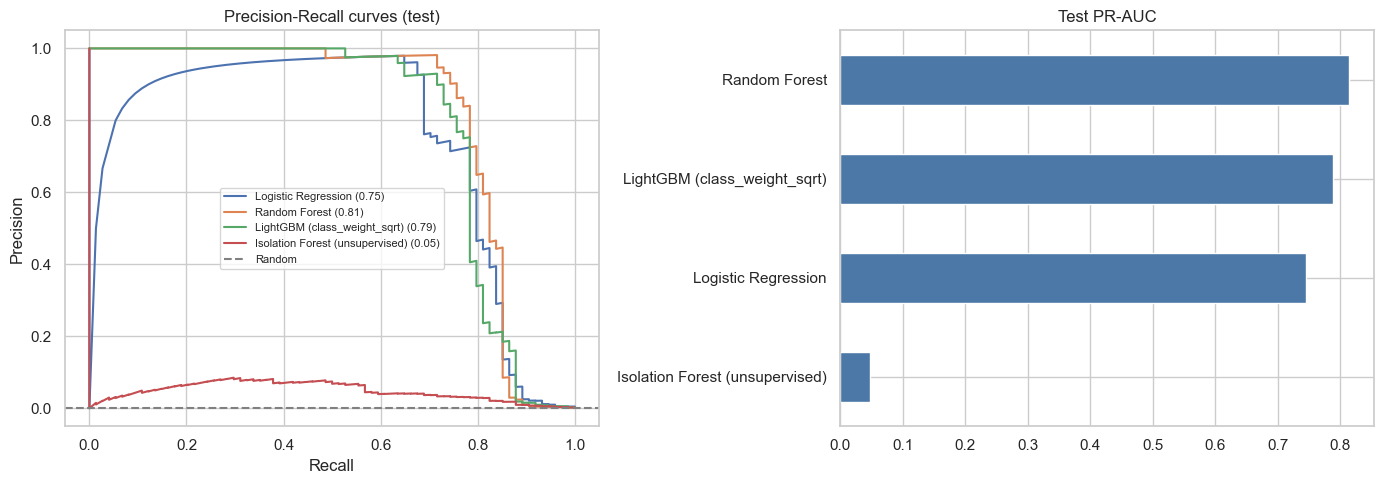

In [57]:
final_lgbm = strategies[best_strategy]

lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=3, max_depth=14,
                            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
iso = IsolationForest(n_estimators=300, random_state=SEED, n_jobs=-1)
lr.fit(Xtr, ytr); rf.fit(Xtr, ytr); iso.fit(Xtr)            # Isolation Forest never sees labels

test_scores = {
    "Logistic Regression": lr.predict_proba(Xte)[:, 1],
    "Random Forest": rf.predict_proba(Xte)[:, 1],
    f"LightGBM ({best_strategy})": final_lgbm.predict_proba(Xte)[:, 1],
    "Isolation Forest (unsupervised)": -iso.decision_function(Xte),
}

def bootstrap_ci(y_true, score, n_boot=300, seed=SEED):
    r = np.random.default_rng(seed); vals = []
    for _ in range(n_boot):
        i = r.integers(0, len(y_true), len(y_true))
        if y_true[i].sum() > 0: vals.append(average_precision_score(y_true[i], score[i]))
    return np.percentile(vals, [2.5, 97.5])

res = pd.DataFrame({k: evaluate(yte, s) for k, s in test_scores.items()}).T
ci = {k: bootstrap_ci(yte, s) for k, s in test_scores.items()}
res["PR_AUC_95%CI"] = [f"[{ci[k][0]:.3f}, {ci[k][1]:.3f}]" for k in res.index]
res = res.sort_values("PR_AUC", ascending=False)
print(f"Test fraud rate (random-classifier PR-AUC) = {yte.mean():.4f}  |  frauds in test = {int(yte.sum())}")
display(res.style.format({"PR_AUC": "{:.3f}", "ROC_AUC": "{:.3f}", "Recall@P80": "{:.3f}"}).highlight_max(subset=["PR_AUC"], color="#c7e9c0"))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, s in test_scores.items():
    p, r, _ = precision_recall_curve(yte, s); ax[0].plot(r, p, label=f"{name} ({average_precision_score(yte, s):.2f})")
ax[0].axhline(yte.mean(), ls="--", c="grey", label="Random"); ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision")
ax[0].set_title("Precision-Recall curves (test)"); ax[0].legend(fontsize=8)
res.PR_AUC.sort_values().plot.barh(ax=ax[1], color="#4C78A8"); ax[1].set_title("Test PR-AUC")
plt.tight_layout(); plt.show()

On this test set the three supervised models are statistically indistinguishable; LightGBM was selected on validation PR-AUC and kept for the downstream steps.

## Step 6. Why the time-based split matters

Many tutorials use a random stratified split. Here I train the same LightGBM recipe (class weights sqrt) both ways and
compare. A random split lets the model train on transactions from *after* some of its test transactions, so
fraud bursts straddle both sets. A higher random-split score suggests optimism from that leakage; with so few frauds the gap can also be small or noisy, which is itself worth knowing.

In [89]:
seeds = [41, 42, 43, 44, 45, 46, 47, 48, 49, 50]
avg_ap_random = 0.0
avg_fraud_rate = 0.0

for s in seeds:
    tr_r, te_r = train_test_split(pos, train_size=0.6, test_size=0.2, stratify=y, random_state=s)
    m_rand = make_lgbm(scale_pos_weight=np.sqrt((y[tr_r] == 0).sum() / (y[tr_r] == 1).sum()),
                   min_child_samples=50, reg_lambda=5).fit(X.iloc[tr_r], y[tr_r])
    avg_ap_random = avg_ap_random + average_precision_score(y[te_r], m_rand.predict_proba(X.iloc[te_r])[:, 1])
    avg_fraud_rate = avg_fraud_rate + np.mean(y[te_r] == 1)
avg_ap_random = avg_ap_random / 10  
avg_fraud_rate = avg_fraud_rate / 10

ap_temporal = average_precision_score(yte, strategies["class_weight_sqrt"].predict_proba(Xte)[:, 1])

cmp = pd.DataFrame({"PR_AUC": [avg_ap_random, ap_temporal]}, index=["Random stratified split", "Chronological split"])
display(cmp)
print(f"Difference: {avg_ap_random - ap_temporal:+.3f} PR-AUC (average random split over 10 seeds minus chronological). "
      f"Test sets differ, so read this as indicative, not exact.")
print(f"average fraud rate over 10 seeds: {avg_fraud_rate*100:+.2f}%")
print(f"chronological fraud rate: {np.mean(yte)*100:.2f}%")

,PR_AUC
Random stratified split,0.853
Chronological split,0.788


Difference: +0.064 PR-AUC (average random split over 10 seeds minus chronological). Test sets differ, so read this as indicative, not exact.
average fraud rate over 10 seeds: +0.17%
chronological fraud rate: 0.13%


Averaged over 10 random splits, PR-AUC was 0.853, versus 0.788 for the chronological split. The two test sets have
different fraud rates (0.17% vs. 0.13%) and only ~100 frauds each, so treat the gap as indicative. A chronological
split remains the right choice because it mirrors production use: score future transactions with a past model.

## Step 7. Cost-sensitive threshold optimisation

F1 treats every error equally, but fraud errors are not equal. This dataset includes the real `Amount`, so we can use it:

- **Missed fraud (false negative)** costs the **transaction amount**
- **False alarm (false positive)** costs a flat **$5** (analyst review + customer friction)

Scan thresholds on **validation** set, pick the one with the lowest total cost, then apply it unchanged to **test** set,
comparing it with the default 0.5 and the F1-optimal threshold.

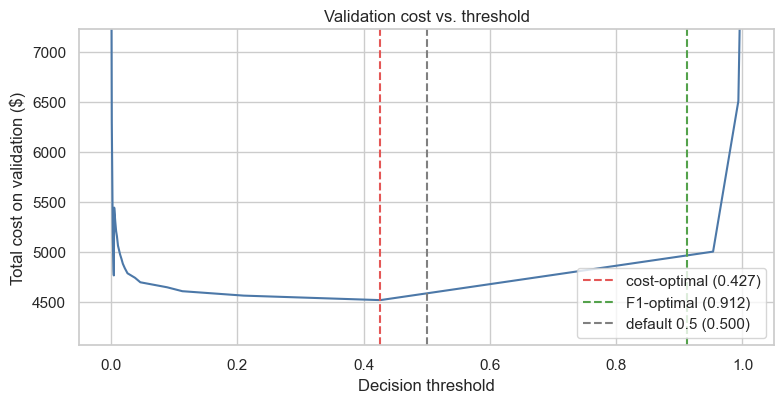

,threshold,alerts,frauds_caught,frauds_missed,false_alarms,fraud_loss,review_cost,total_cost,savings_vs_no_model,savings_%
No model (miss everything),nan,0,0,74,0,"$7,728",$0,"$7,728",$0,0.0%
Default threshold 0.5,0.500,71,56,18,15,"$2,715",$75,"$2,790","$4,938",63.9%
F1-optimal threshold,0.912,58,53,21,5,"$3,718",$25,"$3,743","$3,984",51.6%
Cost-optimal threshold,0.427,72,56,18,16,"$2,715",$80,"$2,795","$4,933",63.8%


In [85]:
FP_COST = 5.0 # False Alarm cost
s_va = final_lgbm.predict_proba(Xva)[:, 1] # prediction score of validation set. i.e. probabilities
s_te = final_lgbm.predict_proba(Xte)[:, 1] # prediction score of test set. i.e. probabilities

"""
For a given threshold, if the prediction probability is over the threshold, we flag the transaction as an alert for fraud.
fn - false negative (missed fraud) if we do not alert fraud but it is actually fraud.
fp - false positive (false alarm) if we alert fraud but it is not actually fraud.
tp - true positive (correctly identified fraud) if the transaction is alerted as fraud and is actually fraud.
"""
def confusion_cost(y_true, score, amt, thr):
    flag = score >= thr
    fn, fp, tp = (~flag) & (y_true == 1), flag & (y_true == 0), flag & (y_true == 1)
    return dict(threshold=thr, alerts=int(flag.sum()), frauds_caught=int(tp.sum()), frauds_missed=int(fn.sum()),
                false_alarms=int(fp.sum()), fraud_loss=amt[fn].sum(), review_cost=FP_COST * fp.sum(),
                total_cost=amt[fn].sum() + FP_COST * fp.sum())

grid = np.unique(np.quantile(s_va, np.linspace(0.90, 0.99995, 600)))
val_costs = np.array([confusion_cost(yva, s_va, amt_va, t)["total_cost"] for t in grid])
thr_cost = grid[val_costs.argmin()]

# Precision = TP / (TP + FP): of the alerts raised, the fraction that were real fraud.
# Recall = TP / (TP + FN): of all real frauds, the fraction you caught.
# thr_pr (the thresholds).
prec, rec, thr_pr = precision_recall_curve(yva, s_va)
# F1 is the harmonic mean of precision (P) and recall (R):
# F1 = 2PR / (P + R)
# [:-1] drops that extra appended point so the arrays line up one-to-one with thr_pr.
# 1e-12 is a tiny number added to the denominator to avoid dividing by zero when both P and R are 0.
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
# pick the best threshold
thr_f1 = thr_pr[f1.argmax()]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(grid, val_costs, c="#4C78A8"); ax.set_xlabel("Decision threshold"); ax.set_ylabel("Total cost on validation ($)")
for t, lab, c in [(thr_cost, "cost-optimal", "#E45756"), (thr_f1, "F1-optimal", "#54A24B"), (0.5, "default 0.5", "grey")]:
    ax.axvline(t, ls="--", c=c, label=f"{lab} ({t:.3f})")
ax.set_ylim(grid_min := val_costs.min() * 0.9, val_costs.min() * 1.6)
ax.set_title("Validation cost vs. threshold"); ax.legend(); plt.tight_layout(); plt.show()

no_model_cost = amt_te[yte == 1].sum()
rows = {"No model (miss everything)": dict(threshold=np.nan, alerts=0, frauds_caught=0, frauds_missed=int(yte.sum()),
                                           false_alarms=0, fraud_loss=no_model_cost, review_cost=0.0, total_cost=no_model_cost)}
for lab, t in [("Default threshold 0.5", 0.5), ("F1-optimal threshold", thr_f1), ("Cost-optimal threshold", thr_cost)]:
    rows[lab] = confusion_cost(yte, s_te, amt_te, t)
cost_tbl = pd.DataFrame(rows).T
cost_tbl["savings_vs_no_model"] = no_model_cost - cost_tbl.total_cost
cost_tbl["savings_%"] = cost_tbl.savings_vs_no_model / no_model_cost * 100
display(cost_tbl.style.format({"threshold": "{:.3f}", "fraud_loss": "${:,.0f}", "review_cost": "${:,.0f}",
                               "total_cost": "${:,.0f}", "savings_vs_no_model": "${:,.0f}", "savings_%": "{:.1f}%",
                               "alerts": "{:,.0f}", "frauds_caught": "{:,.0f}", "frauds_missed": "{:,.0f}",
                               "false_alarms": "{:,.0f}"}))

The validation cost curve is nearly flat between thresholds of about 0.05 and  about 0.9, so the model is robust to the exact
cutoff and the "optimal" threshold (0.427) should not be over-interpreted. On the test set it performs the same as
the default 0.5 (63.8\% vs. 63.9\% cost reduction). The F1-optimal threshold is clearly worse (51.6\%), because F1
weights a missed fraud (about 104 dollars on average) the same as a false alarm (\$5). The takeaway is to optimise the metric
that matches the business cost, not necessarily to tune the threshold finely.

## Step 8. Explainability with SHAP

Regulated institutions must be able to justify why a transaction was flagged. SHAP attributes each prediction to
the input features. First the global view, then per-alert explanations.

**Caveat:** `V1`-`V28` are anonymised, so explanations read "V14 pushed the score up" rather than
"purchase was 3,000 km from home." In production, the same code would run on named features.

How to read it\
Each dot is one transaction from the test sample (all 74 test frauds plus 3,000 legitimate ones).
Horizontal position is the SHAP value: how much that feature pushed that transaction’s score. Right means toward fraud, left means toward legitimate, and 0 means no effect.
Colour is the feature’s value: red is high, blue is low.
Rows are sorted by overall importance, the average absolute SHAP value, so V14 matters most.
The units are log-odds. A SHAP of +2 multiplies the odds of fraud by about e² ≈ 7, and +8 by about 3,000. The scale is distorted by the class weighting, so don’t read the scores as true probabilities. The relative pattern is still valid.

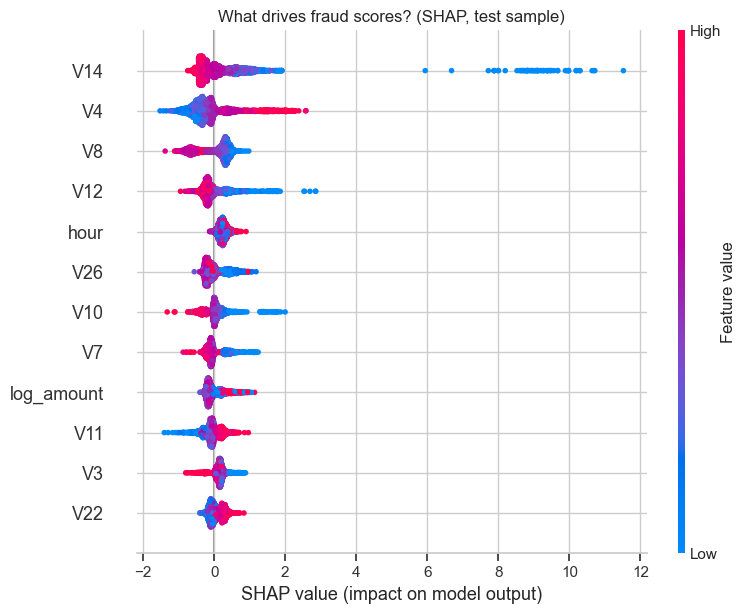

In [86]:
explainer = shap.TreeExplainer(final_lgbm)

def shap_matrix(Xdf):
    sv = explainer.shap_values(Xdf)
    if isinstance(sv, list): sv = sv[1]
    sv = np.asarray(sv)
    return sv[:, :, 1] if sv.ndim == 3 else sv

rng = np.random.default_rng(SEED)
te_idx = np.where(test)[0] # test is indicies
legit_te = te_idx[yte == 0]
sample = np.concatenate([te_idx[yte == 1], rng.choice(legit_te, min(3000, len(legit_te)), replace=False)])
sv_global = shap_matrix(X.iloc[sample])
shap.summary_plot(sv_global, X.iloc[sample], max_display=12, show=False)
plt.title("What drives fraud scores? (SHAP, test sample)"); plt.tight_layout(); plt.show()

SHAP shows that the model relies mainly on a few anonymised components. Low values of V14, V12 and V10 and high values
of V4 push the fraud score up, with V14 the dominant driver (SHAP up to about +11 log-odds for a subset of frauds).
`log_amount` and `hour` contribute little once the V features are included. Caveats: the sample over-represents
fraud (all 74 test frauds plus 3,000 legitimate rows), so the ranking reflects behaviour on fraudulent rows;
the components are anonymised, so the pattern can't be tied to a business explanation; and heavy reliance on
V14 would make the model vulnerable if fraud patterns shifted.

ALERT  t =  44.8 h | $0.38 | risk score 1.00 | actual: FRAUD
   - V14 = -8.39  (SHAP +8.75)
   - V12 = -5.99  (SHAP +1.66)
   - V10 = -7.51  (SHAP +1.38) 

ALERT  t =  43.0 h | $0.77 | risk score 1.00 | actual: FRAUD
   - V14 = -12.45  (SHAP +9.10)
   - V4 = 7.14  (SHAP +2.10)
   - V12 = -6.12  (SHAP +1.51) 

ALERT  t =  47.2 h | $245.00 | risk score 1.00 | actual: FRAUD
   - V14 = -6.42  (SHAP +9.68)
   - V12 = -5.03  (SHAP +1.71)
   - V10 = -5.25  (SHAP +1.41) 

ALERT  t =  43.2 h | $94.82 | risk score 1.00 | actual: FRAUD
   - V14 = -8.56  (SHAP +8.89)
   - V4 = 3.11  (SHAP +1.98)
   - V12 = -5.52  (SHAP +1.75) 

ALERT  t =  42.9 h | $1.00 | risk score 0.64 | actual: legit
   - V14 = -3.91  (SHAP +9.18)
   - V15 = -1.49  (SHAP +1.89)
   - V4 = 4.11  (SHAP +1.48) 



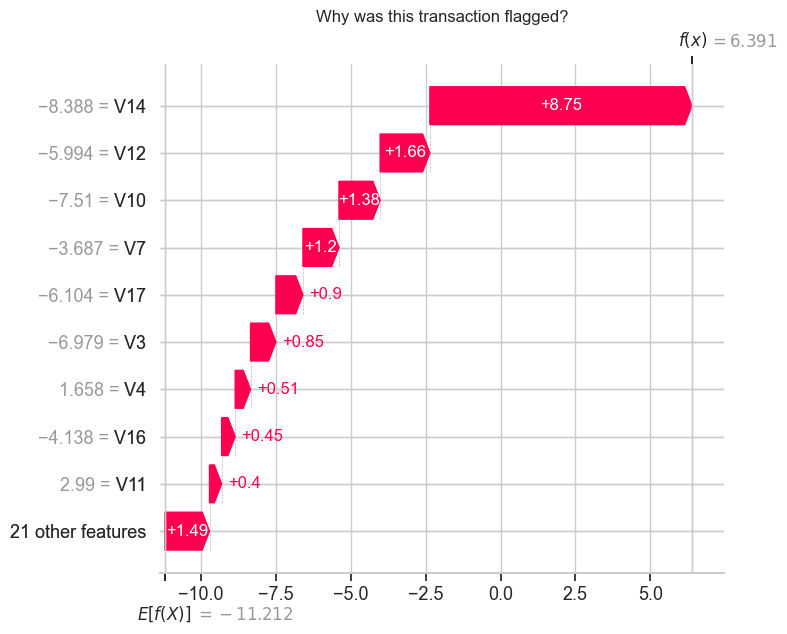

In [87]:
def alert_card(row_pos, k=3):
    row = X.iloc[[row_pos]] # grab the transaction from the transformed dataset 
    sv = shap_matrix(row)[0] # compute its SHAP values for V1-V28,hour,log_amount
    top = [i for i in np.argsort(-sv)[:k] if sv[i] > 0] # Pick the top k=3 SHAP values.
    r = df.iloc[row_pos] # grab original data Time and log_amount
    head = (f"ALERT  t = {r.Time / 3600:5.1f} h | ${r.Amount:,.2f} | risk score {final_lgbm.predict_proba(row)[0, 1]:.2f} "
            f"| actual: {'FRAUD' if r.Class else 'legit'}")
    return head + "\n" + "\n".join(f"   - {X.columns[i]} = {row.iloc[0, i]:.2f}  (SHAP {sv[i]:+.2f})" for i in top) # the top k SHAP values.

flagged = np.where(test)[0][s_te >= thr_cost] # test flagged scores larger than threshold cost. i.e. test alerts
caught = flagged[y[flagged] == 1] # The ones that were fraud and correctly identified.
false_pos = flagged[y[flagged] == 0] # The ones flagged as fraud but were actually not fraud.
rng = np.random.default_rng(7)

demo = list(rng.choice(caught, min(4, len(caught)), replace=False)) if len(caught) else [] # Pick random without replacement at most 4 caught trans.
if len(false_pos): demo += list(rng.choice(false_pos, 1, replace=False)) # If there are false positives, choose one at random for demo.
for p in demo:
    print(alert_card(p), "\n")

# waterfall for first caught fraud from demo.
if len(demo):
    row = X.iloc[[demo[0]]]
    base = float(np.ravel(explainer.expected_value)[-1])
    shap.plots.waterfall(shap.Explanation(values=shap_matrix(row)[0], base_values=base,
                                          data=row.iloc[0].values, feature_names=list(X.columns)),
                         max_display=10, show=False)
    plt.title("Why was this transaction flagged?"); plt.tight_layout(); plt.show()

## How to read the waterfall

The first alert in the list (the $0.38 fraud), drawn as a running total in log-odds.

- **Start at the bottom.** `E[f(X)] = -11.2` is the model's average raw output across the data. It's very negative because most transactions are clearly legitimate. It is the average of the raw scores, not the log-odds of the 0.1% fraud rate, so don't read it as a base rate.
- **Each bar is one feature's push.** V14 = -8.39 adds **+8.75**, V12 adds +1.66, V10 adds +1.38, and so on. The 21 remaining features add +1.49 together.
- **The top is the final score.** -11.2 + 8.75 + 1.66 + ... + 1.49 ≈ **6.39**. As a probability that's 1/(1+e⁻⁶·³⁹) ≈ 99.8%, which matches the "risk score 1.00" on the card.
- **The numbers on the left** are this transaction's actual feature values. Every bar is red, so nothing pushed the score down here.

This is SHAP's main strength: the contributions add up exactly to the score, so the explanation is faithful to the model.

Per-alert SHAP shows why each transaction was flagged. The contributions sum exactly to the model's log-odds score
(e.g. -11.2 baseline + 17.6 total push = 6.39, or ~99.8% fraud probability). In all four correctly flagged frauds,
a low V14 contributes +8.7 to +9.7 log-odds, with V12, V10 and V4 adding smaller confirming pushes. The effect of
V14 saturates below about -4, as expected from threshold-based tree splits. The one false positive in the sample
has the same V14 signal but weaker supporting evidence (score 0.64 vs. ~1.00 for the frauds), so it is the kind of
borderline alert a human reviewer would triage. Because the features are anonymised, these explanations identify
what drives the model, not the real-world cause of fraud.

## Step 8 Business impact summary

In [88]:
best = cost_tbl.loc["Cost-optimal threshold"]
test_hours = (df.Time[test].max() - df.Time[test].min()) / 3600
total_fraud_usd = no_model_cost
caught_usd = amt_te[(s_te >= thr_cost) & (yte == 1)].sum()

display(Markdown(f'''
**Test period ({test_hours:.1f} hours, {len(yte):,} transactions, {int(yte.sum())} fraudulent):**

- Fraud dollars at risk with no model: **\${total_fraud_usd:,.0f}**
- Fraud dollars stopped at the cost-optimal threshold: **\${caught_usd:,.0f}** ({caught_usd / max(total_fraud_usd, 1):.0%})
- Frauds caught: **{int(best.frauds_caught)} of {int(yte.sum())}** ({best.frauds_caught / yte.sum():.0%} recall)
- Alerts raised: **{int(best.alerts)}** (~{best.alerts / test_hours:.1f} per hour), of which {int(best.false_alarms)} were false alarms
- Net cost reduction vs. no model (after paying \${FP_COST:.0f} per false alarm): **\${best.savings_vs_no_model:,.0f}** ({best["savings_%"]:.0f}%)
'''))


**Test period (7.7 hours, 56,746 transactions, 74 fraudulent):**

- Fraud dollars at risk with no model: **\$7,728**
- Fraud dollars stopped at the cost-optimal threshold: **\$5,013** (65%)
- Frauds caught: **56 of 74** (76% recall)
- Alerts raised: **72** (~9.4 per hour), of which 16 were false alarms
- Net cost reduction vs. no model (after paying \$5 per false alarm): **\$4,933** (64%)


## Limitations
**Limitations**
- **Anonymised features.** PCA components prevent domain feature engineering (geo-velocity, customer baselines,
  merchant risk) and make explanations abstract.
- **Only two days of data.** No seasonality, no meaningful concept-drift analysis, and few frauds in each split, so
  metrics are noisy (hence the bootstrap intervals).
- **Dated, heavily studied benchmark.** Collected in 2013 from European cardholders; strong benchmark scores don't
  imply real-world performance on today's fraud.
- **Simplified costs.** Flat $5 review cost and "loss = amount" ignore chargeback fees, recovery rates and customer lifetime value.
- **Threshold stability.** The threshold is tuned on one validation window and would need ongoing re-tuning in production.